# **IS 4487 Assignment 11: Predicting Airbnb Prices with Regression**

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using Regularization
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## **Task 1. Load Your Transformed Airbnb Dataset**

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### 🔧 Write code for the following:

1.1. Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

1.2. Use `pandas` to load and preview the dataset - call `.info()` and `.head()` and anything else you want



'cleaned_airbnb_data_7.csv' not found locally. Downloading backup dataset...
Successfully downloaded backup Airbnb dataset from GitHub!

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 459 entries, 0 to 458
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            459 non-null    int64  
 1   listing_url                                   459 non-null    object 
 2   scrape_id                                     459 non-null    int64  
 3   last_scraped                                  459 non-null    object 
 4   source                                        459 non-null    object 
 5   name                                          459 non-null    object 
 6   description                                   449 non-null    object 
 7   neighborhood_overview                         196 non-nul

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### ✍️ Please answer the following:

1.3. What business information does the dataset include?

1.4. How many rows and columns are present?




✍️ Your Response:

1.3. This dataset has information on host details, pricing, reviews/scores, and booking availabilities.

1.4. Rows = 459 and Columns = 76

## **Task 2. Drop Columns Not Useful for Modeling**

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### 🔧 Write code to do the following:

2.1. Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they're still in your dataset



Dropped 19 columns.
Remaining columns: 58


,host_since,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2013-01-07,NaN,NaN,50%,f,1,5,"['email', 'phone']",t,t,...,4.22,4.56,3.22,3.67,0,1,1,0,0,0.07
1,2014-08-07,within an hour,100%,100%,t,4,6,"['email', 'phone']",t,t,...,4.85,4.81,4.81,4.77,0,4,4,0,0,2.32
2,2015-03-13,within an hour,100%,99%,f,2,2,"['email', 'phone', 'work_email']",t,t,...,4.81,4.88,4.76,4.64,0,2,1,1,0,2.97
3,2014-08-07,within an hour,100%,100%,t,4,6,"['email', 'phone']",t,t,...,4.83,4.70,4.80,4.72,0,4,4,0,0,2.68
4,2014-07-07,NaN,NaN,100%,t,1,1,"['email', 'phone']",t,t,...,4.95,4.93,4.87,4.77,0,1,1,0,0,5.67


✍️ Please answer the following:

2.2. What columns did you drop, and why?

2.3. What risks might occur if you included them in your model?

✍️ Your Response:

2.2. I dropped the columns like id#, names, descriptions, host names, etc. I dropped them because these columns contained texted cells that are not numerical or needed in explaining pricing.

2.3. Risks of keeping them in is, overfitting, larger database and complexities, and the data dropped is not even going to be used so why keep it in.

## **Task 3. Explore Relationships Between Numeric Features**

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### 🔧 Write code to do the following:

3.1. Generate a correlation matrix




--- Correlations with Price ---
price                                           1.000000
accommodates                                    0.579588
beds                                            0.547032
bedrooms                                        0.499286
bathrooms                                       0.468030
estimated_revenue_l365d                         0.249488
maximum_maximum_nights                          0.122872
minimum_maximum_nights                          0.112166
maximum_nights_avg_ntm                          0.111271
availability_30                                 0.108409
availability_60                                 0.060509
availability_90                                 0.040997
calculated_host_listings_count_entire_homes     0.033206
availability_eoy                                0.032537
review_scores_value                             0.018269
maximum_nights                                  0.017992
calculated_host_listings_count                  0.015773

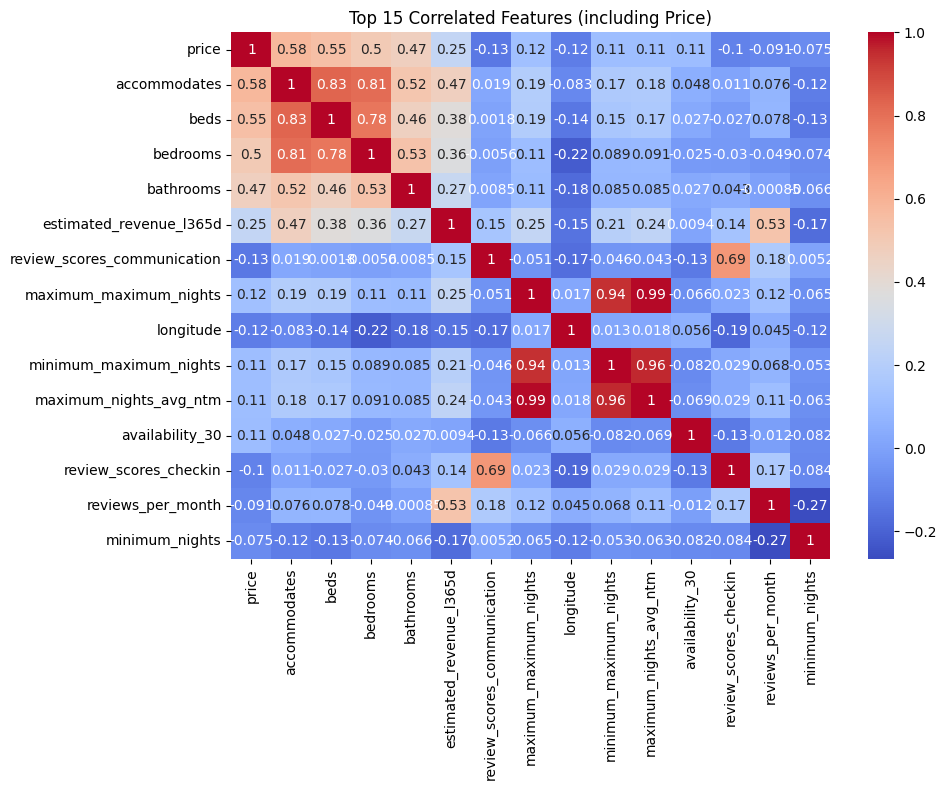

✍️ Please answer the following questions:
3.2. Which variables had the strongest positive or negative correlation with price?

3.3. Which variables might be useful predictors of price?

✍️ Your Response:
3.3.The Strongest Postive correlation is Accommodates (0.58) and Negative correclation is review scores communication (-0.13)

3.4. Useful predictors of price is Accomodates, beds, bedrooms, and bathrooms.

## **Task 4. Define Features and Target Variable**

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### 🔧 Write code to do the following:

4.1. Set `price` as your target variable

4.2. Remove `price` from your predictors



Target (y) shape: (459,)
Features (X) shape: (459, 40)

Predictor features selected:
['host_listings_count', 'host_total_listings_count', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'instant_bookable', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_ho

✍️ Please answer the following questions:

4.3. What features are you using as predictors?

4.4. Why is this a regression problem and not a classification problem?

✍️ Your Response:

4.3. The features I will be using as predictors are predicitors with a high correclation and Ai sugguested to use a total of 40 predictors.

4.4. This is a regression problem because we are trying to only predict one target variable and that is Price.

## **Task 5. Split Data into Training and Testing Sets**


**Business framing:**

Splitting your data lets you train a model and test how well it performs on new, unseen data.

### 🔧 Write code to do the following:

5.1.  Use `train_test_split()` to split into 80% training, 20% testing

***CAVEAT: Ideally we should split our data before doing any transformations that are data dependent. However in this case, we will make an exception as our data was already processed/transformed, or we owuld have to start from scratch. Just remember to only perform pre-processing/cleaning tasks do not peak into the test set.***





X_train shape: (367, 40)
X_test shape: (92, 40)
y_train shape: (367,)
y_test shape: (92,)


## **Task 6. Fit a Linear Regression Model**

**Business framing:**

Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### 🔧 Write code to do the following:

6.1. Fit a linear regression model to your training data

6.2. Use it to predict prices for the train and test set



Baseline Linear Regression Model trained successfully!
Predictions generated: 367 train predictions, 92 test predictions.


## **Task 7. Evaluate Model Performance**

**Business framing:**

A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### 🔧 Write code to do the following:

7.1. Print MSE and R² score for your model


=== Training Set Metrics ===
Mean Squared Error (MSE): 4400.96
R² Score: 0.5669

=== Testing Set Metrics ===
Mean Squared Error (MSE): 8752.53
R² Score: -0.5595


7.2. What is your R² score? How well does your model explain price variation?

7.3. Is your MSE large or small? What could you do to improve/lower it?

✍️ Your Response:

7.2. The training R2 model gives us a 0.57 but our test model is giving us a -0.56 score. So our test model is failing somewhere and needs some fixing.

7.3. The training model has a MSE of 4400.96 and the test is at 8752.53. So our test model probably has overfitting.

## **Task 8. Interpret Model Coefficients**

**Business framing:**

The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### 🔧 Write code to do the following:

8.1. Create a table showing feature names and regression coefficients

8.2. Sort the table so that the most impactful features (absolute magnitude-wise) are at the top


,Feature,Coefficient
0,latitude,-784.618582
1,longitude,-326.230449
2,review_scores_communication,-137.706179
3,review_scores_value,135.102802
4,review_scores_checkin,-91.976509
5,minimum_nights_avg_ntm,36.504410
6,maximum_minimum_nights,-36.232262
7,bathrooms,32.631440
8,review_scores_cleanliness,-30.029879
9,review_scores_accuracy,20.872583


✍️ Please answer the following:

8.3. Which features increased price the most?

8.4. Were any surprisingly negative?

8.5. What business insight could you draw from this?

✍️ Your Response:

8.3. The features that increase the model that most are Beds (17.17) and Accommodates (16.55)

8.4. The features with a surprisingly negtive result was review score communication. This had a score of -137.71

8.5. The key business insights from this model is that hosts with a high accomation number and high number of beds lead to premium pricing.

## **Task 9. Try to Improve the Linear Regression Model**

**Business framing:**

The first version of your model included all available features — but not all features are equally useful. You can use automated feature engineering first and then regularization to either removing some features or shrink some coefficients, which can often improve test set performance and interpretation.

### 🔧 Write code to do the following:

9.1. Use feature engineering to create several more features. You can use automated or manual engineering.

9.2 Build and train a new regression model. Evaluate it on the train and test set.

9.3. Attempt to do some regularization. Use LassoCV or RidgeCV to find an optimal model by selecting the best value of the `alpha` hyperparameter.  

9.4. Print the optimal value of alpha.
Display the top coefficients for this best model.

9.5. Use this best regularized model to make predictions on the test set. Then evaluate this model on train and test set.



=== Engineered Features Model (OLS) ===
Train R²: 0.5714 | Train MSE: 4355.12
Test R²: -0.5886 | Test MSE: 8916.07



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 705.5649847029708, tolerance: 310.3012928327646
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 6745.681357903173, tolerance: 310.3012928327646
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 10167.510400258703, tolerance: 310.3012928327646
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWa

=== Optimal Lasso Regularization Parameters ===
Optimal Alpha: 3.7649

Top 10 Regularized Coefficients:


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 31274.027178858058, tolerance: 251.8370925170068
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 31252.304622501833, tolerance: 251.8370925170068
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 31232.391275057336, tolerance: 251.8370925170068
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: Convergence

,Feature,Coefficient,Absolute_Coefficient
0,accommodates,22.754454,22.754454
1,bathrooms,20.627793,20.627793
2,review_scores_value,18.356628,18.356628
3,review_scores_communication,-18.018679,18.018679
4,beds,16.556572,16.556572
5,estimated_occupancy_l365d,-14.021802,14.021802
6,estimated_revenue_l365d,11.885642,11.885642
7,review_scores_checkin,-10.237815,10.237815
8,capacity_per_min_night,6.672212,6.672212
9,reviews_per_month,-6.247860,6.247860



=== Regularized Lasso Model Metrics ===
Train MSE: 5118.16
Train R²: 0.4963
Test MSE: 3453.10
Test R²: 0.3847


✍️ Please answer the following:

9.6. Compared to the model with the full set of engineerined features, does the regularized model perform better or worse?

9.7. Does the linear regression model used on this dataset suffer from overfitting or underfitting or neither? Which of these two models does better at dealing with a) overfitting and b) underfitting?

✍️ Your Response:

9.6.The regularized model performs significantly better because it doesn't use any of the negative R squared.

9.7. The baseline regression model has to much overfitting from too many features.


## **10. Reflect and Recommend**

**Business framing:**

Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### ✍️ Please answer the following questions:

10.1. What business question did your model help answer?

10.2. What would you recommend to Airbnb or its hosts? Any insights on useful features?

10.3. What could you do next to improve this model or make it more useful?

10.4. How does this relate to your customized learning outcome you created in canvas?



✍️ Your Response: 🔧

10.1. the model helped answer what physical characteristics (like beds and accommodates) have the strongest influence on setting listing prices.

10.2. I recommend hosts focus on maximizing listing capacity and bed counts to justify premium pricing, since those physical features drive price far more than high review scores.

10.3. To improve this model, we could collect neighborhood/geographic cluster categorical data and encode key amenity text (like 'pool' or 'parking') as binary features.

10.4. This task directly connects to my learning outcome by demonstrating how to diagnose model overfitting on a real dataset and use regularized regressions to construct reliable models.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [1]:
!jupyter nbconvert --to html "assignment_11_ShermanEthan.ipynb"

[NbConvertApp] Converting notebook assignment_11_ShermanEthan.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 672359 bytes to assignment_11_ShermanEthan.html
